# Chapter 02 — Randomized Experiments and Stats Review
Rewritten using the `probability` library (based on Matheus Facure's *Causal Inference in Python*).

In [1]:
import set_paths
import numpy as np
import pandas as pd
from pandas import DataFrame
import matplotlib.pyplot as plt
from make_data import load_cross_sell_email, load_enem_scores
from probability.distributions import (
    BetaBinomialConjugate, Binomial, Boolean, Count, Nominal, Normal, Ratio
)

## 2.1 A/B Testing & Covariate Balance (`cross_sell_email.csv`)
We wrap `cross_sell_email` as a `Nominal` distribution, `conversion` and `gender` as `Boolean` distributions, and `age` as a `Ratio` distribution.

In [2]:
data = load_cross_sell_email()
data.head(5)

,gender,cross_sell_email,age,conversion
0,0,short,15,0
1,1,short,27,0
2,1,long,17,0
3,1,long,34,0
4,1,no_email,14,0


In [3]:
email = Nominal(data["cross_sell_email"])
conversion = Boolean(data["conversion"].astype(bool))
age = Ratio(data["age"])
gender = Boolean(data["gender"].astype(bool))

# Group means conditioned on email treatment arm
DataFrame({
    "n": (conversion | email).lens(),
    "conversion_mean": (conversion | email).mean(),
    "age_mean": (age | email).mean(),
    "gender_mean": (gender | email).mean(),
})

,n,conversion_mean,age_mean,gender_mean
long,109,0.055046,21.752294,0.550459
no_email,94,0.042553,20.489362,0.542553
short,120,0.125000,20.991667,0.633333


In [4]:
# Covariate balance: unweighted standardized mean difference vs. "no_email"
DataFrame({
    "gender_norm_diff": (gender | email).normalized_diff(control="no_email"),
    "age_norm_diff": (age | email).normalized_diff(control="no_email"),
})

,gender_norm_diff,age_norm_diff
long,0.015802,0.221423
no_email,0.000000,0.000000
short,0.184341,0.087370


## 2.2 The Most Dangerous Equation (`enem_scores.csv`)
Using `.ge_quantile()`, `.le_quantile()`, `.logical_or()`, and `.between_quantiles()` to inspect school size by ENEM score quantiles.

In [5]:
df = load_enem_scores()
df.sort_values(by="avg_score", ascending=False).head(10)

,year,school_id,number_of_students,avg_score
16670,2007,33062633,68,82.97
16796,2007,33065403,172,82.04
16668,2005,33062633,59,81.89
16794,2005,33065403,177,81.66
10043,2007,29342880,43,80.32
18121,2007,33152314,14,79.82
16781,2007,33065250,80,79.67
3026,2007,22025740,144,79.52
14636,2007,31311723,222,79.41
17318,2007,33087679,210,79.38


In [6]:
avg_score = Ratio(df["avg_score"])
num_students = Count(df["number_of_students"])

# Top 1% school indicator and 98th-percentile outlier trimming
top_school = avg_score.ge_quantile(0.99)
trimmed_students = num_students.between_quantiles(0.0, 0.98, inclusive="left")

students_by_top = trimmed_students | top_school
DataFrame({
    "mean_students": students_by_top.mean(),
    "median_students": students_by_top.median(),
    "se_students": students_by_top.se(),
})

,mean_students,median_students,se_students
False,129.280324,103.0,0.494986
True,105.369272,77.0,4.549469


Text(0.5, 1.0, 'Number of Students of 1% Top Schools (Right)')

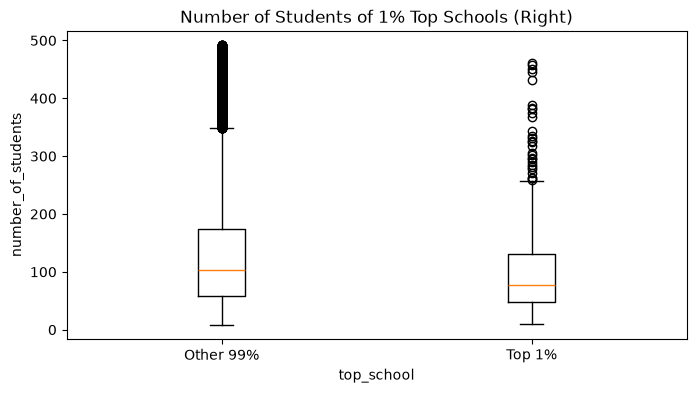

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(
    [students_by_top[False].data, students_by_top[True].data],
    tick_labels=["Other 99%", "Top 1%"]
)
ax.set_xlabel("top_school")
ax.set_ylabel("number_of_students")
ax.set_title("Number of Students of 1% Top Schools (Right)");

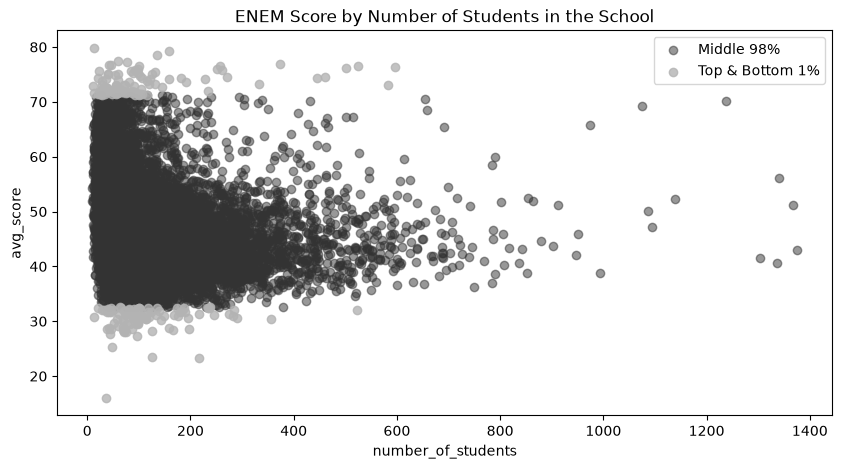

In [8]:
# Scatter plot of Middle vs. Top/Bottom 1% schools
sample_df = df.sample(10_000, random_state=42)
s_score = Ratio(sample_df["avg_score"])
s_students = Count(sample_df["number_of_students"])

extreme = s_score.gt_quantile(0.99).logical_or(s_score.lt_quantile(0.01))
middle = ~extreme

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter((s_students | middle.keep(True)).data, (s_score | middle.keep(True)).data,
           label="Middle 98%", alpha=0.5, color="0.2")
ax.scatter((s_students | extreme.keep(True)).data, (s_score | extreme.keep(True)).data,
           label="Top & Bottom 1%", alpha=0.8, color="0.7")
ax.set_xlabel("number_of_students")
ax.set_ylabel("avg_score")
ax.set_title("ENEM Score by Number of Students in the School")
ax.legend();

## 2.3 Standard Error and Confidence Intervals
Every numeric/boolean distribution and `DataSeries` exposes `.se()` / `.sem()`, `.mean_dist()`, and `.ci()`.

In [9]:
conv_by_email = conversion | email
short_email = conv_by_email["short"]
long_email = conv_by_email["long"]
no_email = conv_by_email["no_email"]

DataFrame({
    "n": conv_by_email.lens(),
    "mean": conv_by_email.mean(),
    "se": conv_by_email.se(),
}).join(conv_by_email.ci(0.95))

,n,mean,se,lower,upper
long,109,0.055046,0.021946,0.012032,0.098059
no_email,94,0.042553,0.020931,0.001530,0.083576
short,120,0.125000,0.030317,0.065580,0.184420


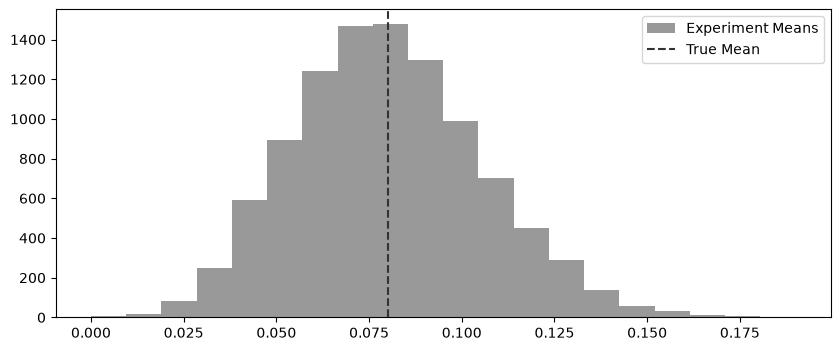

In [10]:
# Sampling distribution of sample means from Binomial(n=100, p=0.08)
binom_exp = Binomial(n=100, p=0.08)
sim_means = binom_exp.rvs(10_000, random_state=42) / 100.0

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(sim_means, bins=20, color="0.6", label="Experiment Means")
ax.axvline(0.08, ls="--", color="0.2", label="True Mean")
ax.legend();

<Axes: xlabel='x', ylabel='$P(X = x)$'>

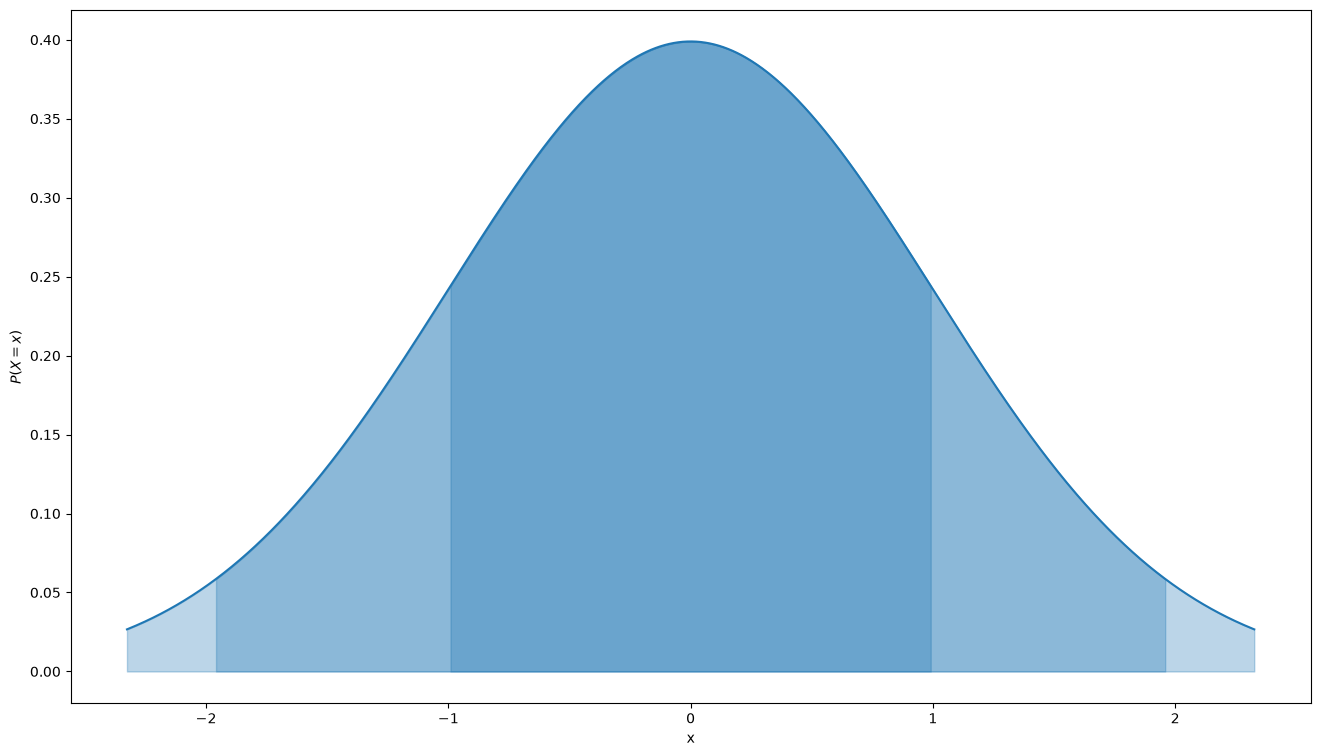

In [11]:
# Standard Normal PDF with shaded 68%, 95%, and 99.7% intervals
Normal.StandardNormal().plot(ci=[0.68, 0.95, 0.997]);

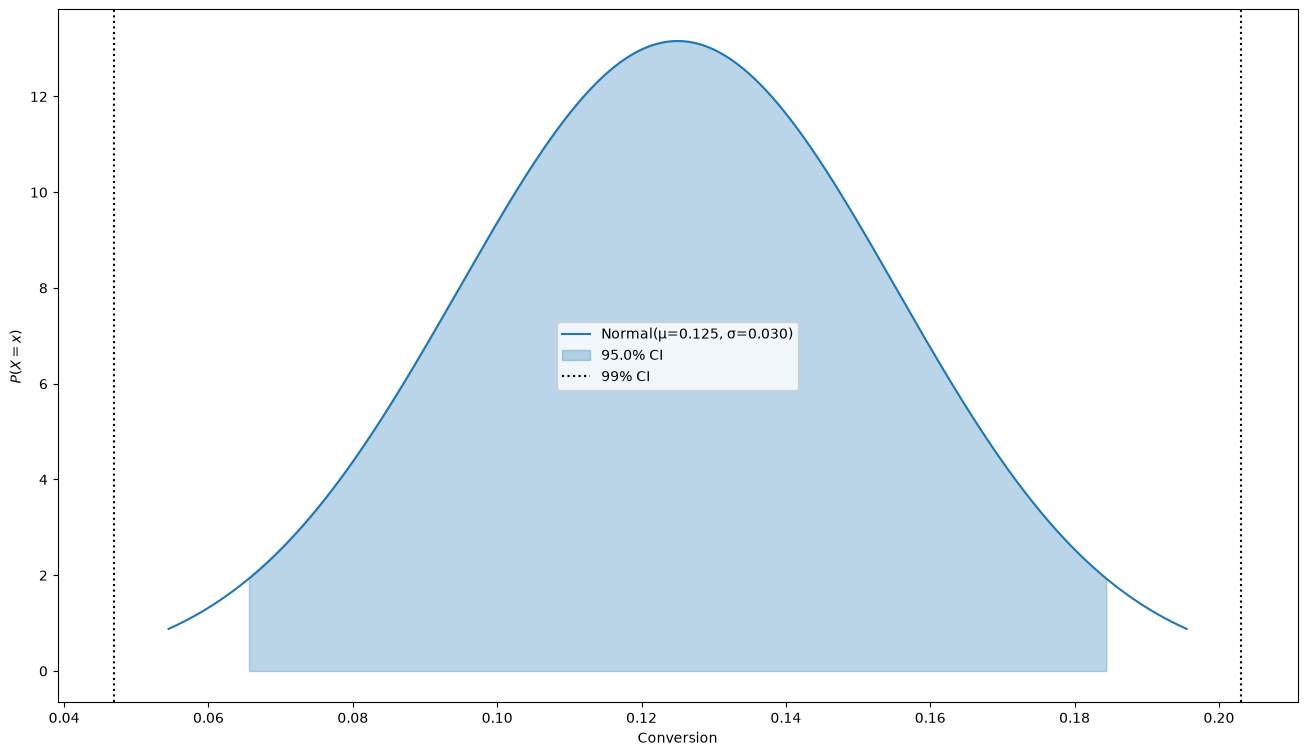

In [12]:
# Sampling distribution of the mean for Short Email with 95% and 99% CIs
ax = short_email.mean_dist().plot(ci=0.95, color="C0")
ci_99 = short_email.ci(0.99)
ax.axvline(ci_99[0], ls=":", color="k", label="99% CI")
ax.axvline(ci_99[1], ls=":", color="k")
ax.set_xlabel("Conversion")
ax.legend();

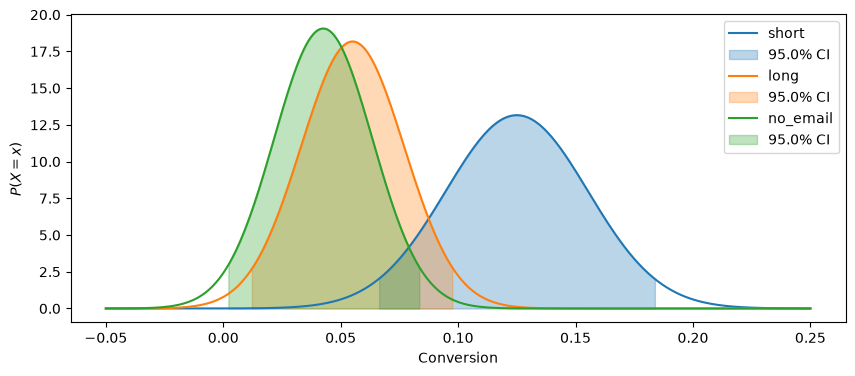

In [13]:
# Comparing Normal sampling distributions of the mean across all 3 arms
fig, ax = plt.subplots(figsize=(10, 4))
x_grid = np.linspace(-0.05, 0.25, 300)
for arm_name, color in [("short", "C0"), ("long", "C1"), ("no_email", "C2")]:
    conv_by_email[arm_name].mean_dist().plot(
        x=x_grid, ci=0.95, color=color, ax=ax, label=arm_name
    )
ax.set_xlabel("Conversion")
ax.legend();

<Axes: title={'center': ' 95% HDIs of $p(p_{conversion}|cross_sell_email)$'}, xlabel='cross_sell_email', ylabel='$p_{conversion}$'>

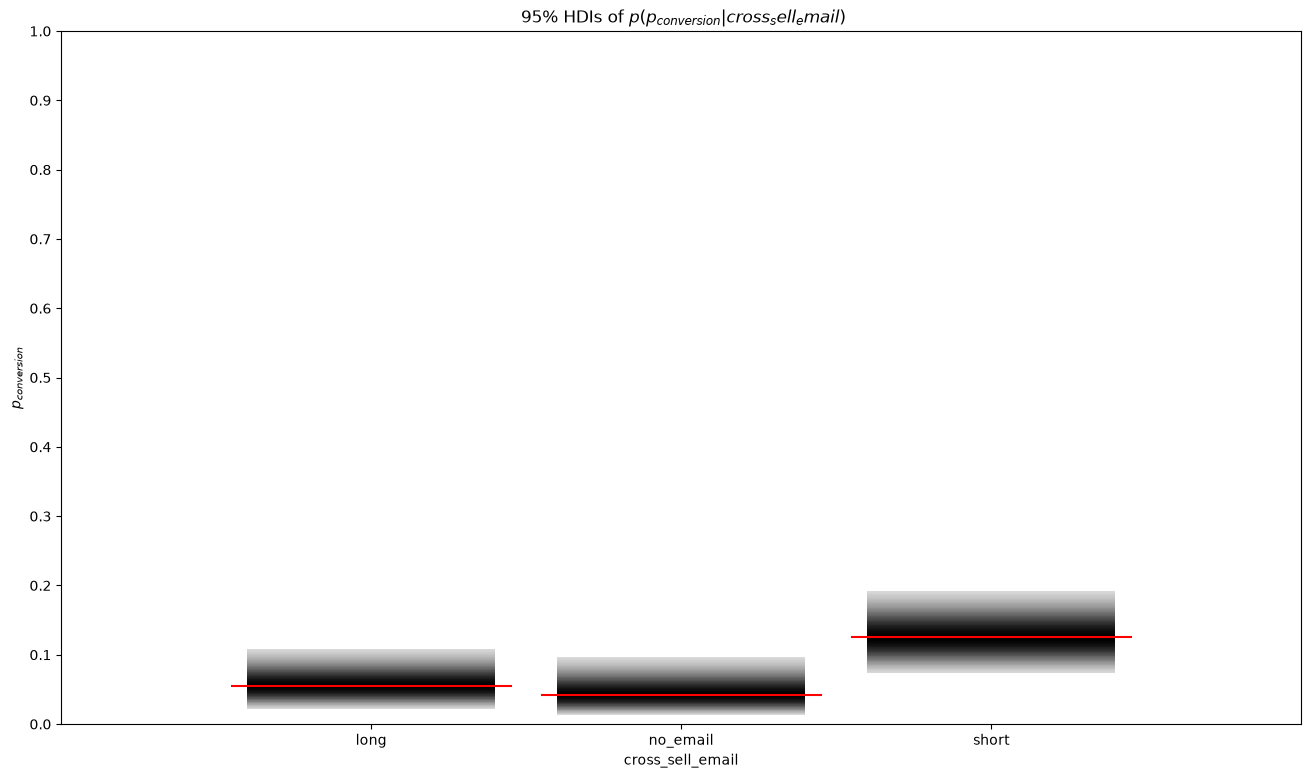

In [14]:
# Bayesian counterpart: exact Beta posterior 95% HDIs via BooleanSeries
conv_by_email.plot_prob_densities(hdi=0.95, color_mean="red");

## 2.4 Hypothesis Testing, P-Values & Sample Size
Linear combinations of `Normal` distributions are closed-form (`N(1, 4) - N(4, 3) == N(-3, 5)`), and `mean_diff`, `mean_diff_ci`, `t_stat`, `p_value`, and `sample_size_for_effect` are built directly into data distributions.

n2 - n1 = Normal(mu=-3, sigma=5.0)


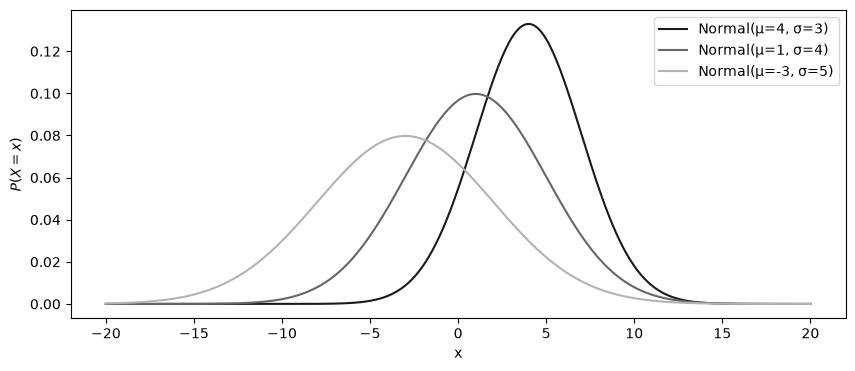

In [15]:
n1 = Normal(mu=4, sigma=3)
n2 = Normal(mu=1, sigma=4)
n_diff = n2 - n1
print("n2 - n1 =", repr(n_diff))

fig, ax = plt.subplots(figsize=(10, 4))
x_grid = np.linspace(-20, 20, 400)
n1.plot(x=x_grid, color="0.1", ax=ax, label=str(n1))
n2.plot(x=x_grid, color="0.4", ax=ax, label=str(n2))
n_diff.plot(x=x_grid, color="0.7", ax=ax, label=str(n_diff))
ax.legend();

Difference distribution: Normal(mu=0.08244680851063829, sigma=0.0368403061409387)
95% CI (H0: diff = 0.00): (0.0102, 0.1547)
95% CI (H0: diff = 0.01): (0.0002, 0.1447)
t-statistic: 2.2380, two-sided p-value: 0.02522


<Axes: xlabel='x', ylabel='$P(X = x)$'>

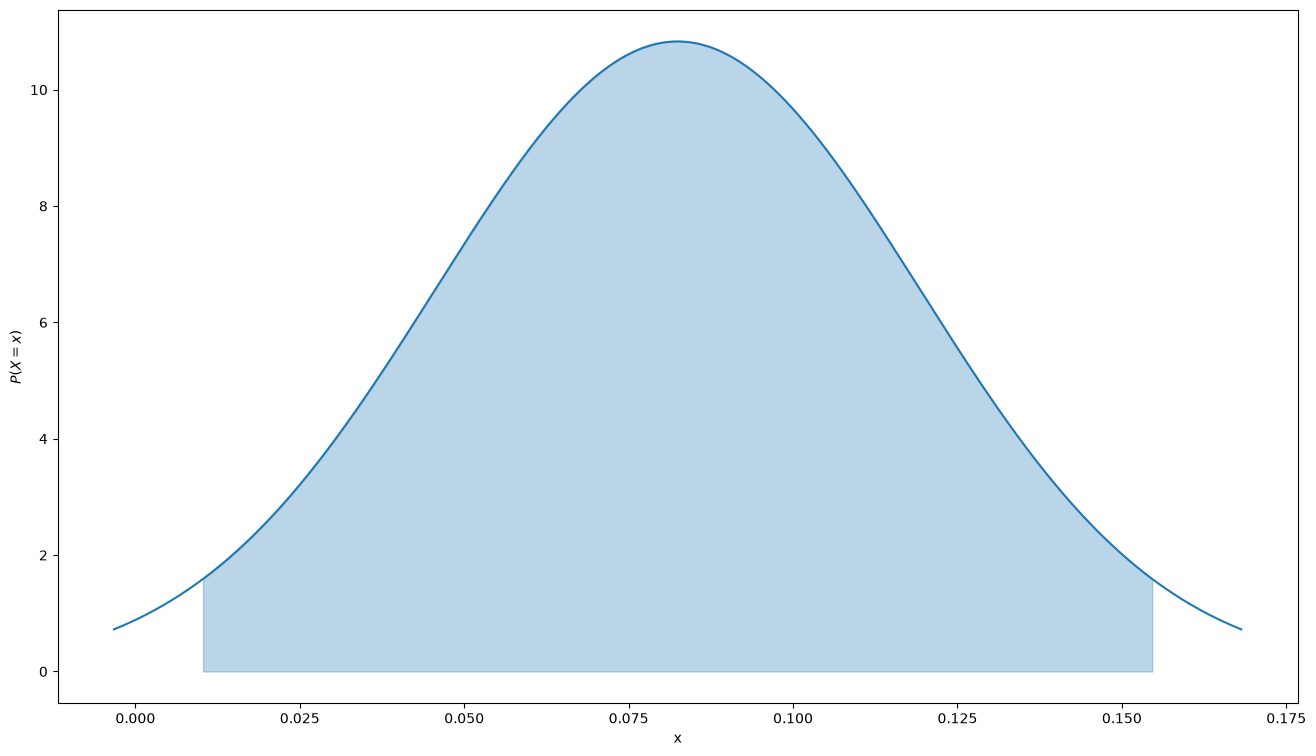

In [16]:
# Difference in conversion: short_email - no_email
diff_dist = short_email.mean_diff(no_email)
ci_95 = short_email.mean_diff_ci(no_email, percent=0.95)
ci_shifted_1pct = short_email.mean_diff_ci(no_email, percent=0.95, null_diff=0.01)
t_stat = short_email.t_stat(no_email)
p_val = short_email.p_value(no_email, two_sided=True)

print("Difference distribution:", repr(diff_dist))
print(f"95% CI (H0: diff = 0.00): ({ci_95[0]:.4f}, {ci_95[1]:.4f})")
print(f"95% CI (H0: diff = 0.01): ({ci_shifted_1pct[0]:.4f}, {ci_shifted_1pct[1]:.4f})")
print(f"t-statistic: {t_stat:.4f}, two-sided p-value: {p_val:.5f}")

diff_dist.plot(ci=0.95);

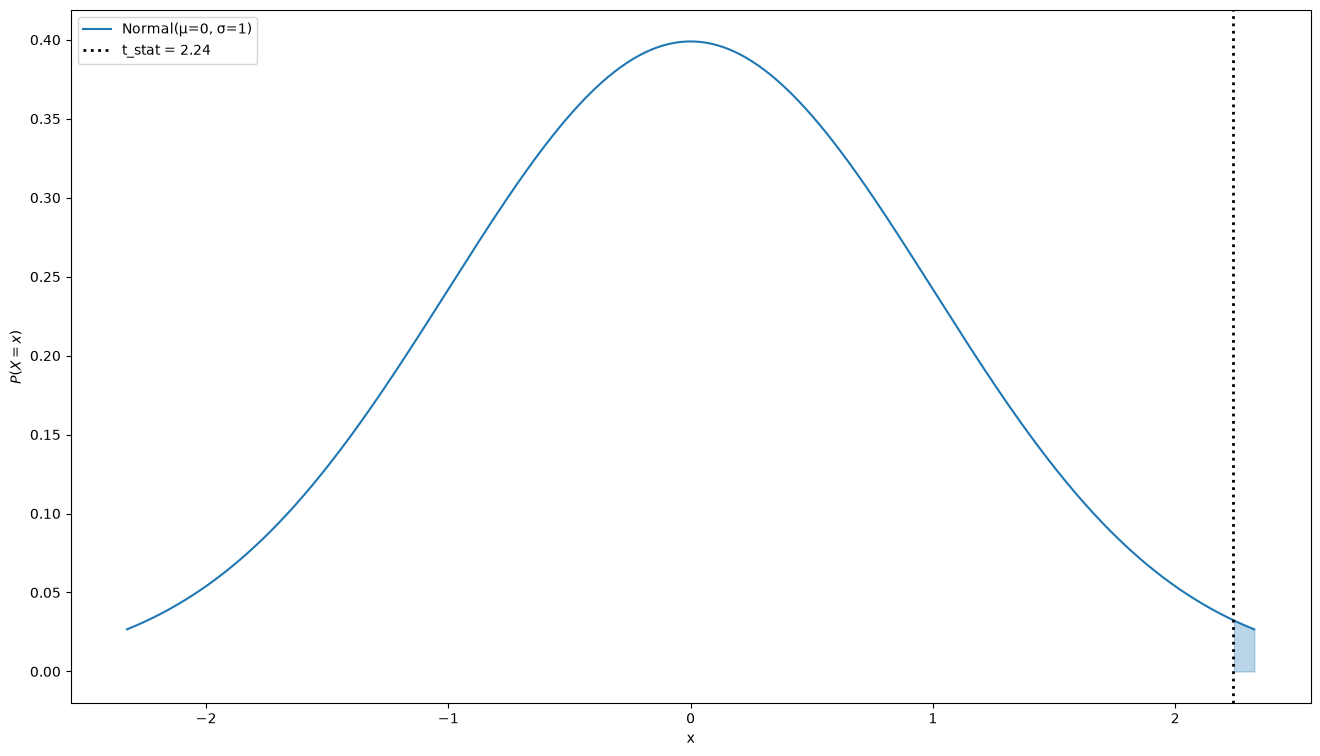

In [17]:
# Visualizing the test statistic and upper-tail p-value on StandardNormal
ax = Normal.StandardNormal().plot(fill_interval=(t_stat, None), color="C0")
ax.axvline(t_stat, ls=":", color="k", lw=2, label=f"t_stat = {t_stat:.2f}")
ax.legend();

In [18]:
# Sample size calculation for an 8% minimum detectable effect (MDE = 0.08)
n_rule_of_16 = no_email.sample_size_for_effect(mde=0.08, approx_16=True)
n_exact = no_email.sample_size_for_effect(mde=0.08, alpha=0.05, power=0.80)
print(f"Required sample size per arm (16 * sigma^2 / delta^2): {n_rule_of_16}")
print(f"Required sample size per arm (exact normal quantiles): {n_exact}")

Required sample size per arm (16 * sigma^2 / delta^2): 103
Required sample size per arm (exact normal quantiles): 102
